# TMDB Movies — Live API Analysis
**Source: TMDB API (`/discover/movie` + `/movie/{id}?append_to_response=credits`) stored locally at `data/tmdb_movies_3000.csv` (2,313 movies), then all analysis runs on the stored file.**
**Libraries: pandas + matplotlib + numpy**
Modules: `module1_tmdb` (fetch/store) → `module1_loader` (load/clean) → `module2_conditions` (if/elif) → `module3_analysis` (loops + numpy) → `module4_stats` (numpy stats) → `module5_visuals` (charts)
Run top to bottom — charts display inline and save to `charts/`.

In [1]:
# Cell 0 — connect all modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import module1_loader
import module1_tmdb
import module2_conditions as cond
import module3_analysis as analysis
import module4_stats as stats
import module5_visuals as visuals
DATA_PATH = "data/tmdb_movies_3000.csv"
CHARTS_DIR = "charts"
print("modules loaded OK")

modules loaded OK


In [2]:
# Cell 1 — MODULE 1: load LOCAL dump (no API hit here; API already stored it)
df = module1_loader.load_tmdb(DATA_PATH)
df = module1_loader.clean_data(df)
n, cols, dtypes = module1_loader.get_summary(df)
complete, total = module1_loader.tmdb_completeness(df)
print(f"rows: {n:,} | cols: {len(cols)}")
print("columns:", cols)
print(f"complete money/runtime rows: {complete}/{total} ({100*complete/total:.1f}%)")
df.head(5)

rows: 2,313 | cols: 17
columns: ['MovieID', 'Title', 'ReleaseDate', 'ReleaseYear', 'Original_Language', 'Rating', 'Vote_Count', 'Popularity', 'Runtime', 'Budget', 'Revenue', 'Cast_Count', 'Crew_Count', 'Genres', 'Primary_Genre', 'Profit', 'ROI']
complete money/runtime rows: 1843/2313 (79.7%)


,MovieID,Title,ReleaseDate,ReleaseYear,Original_Language,Rating,Vote_Count,Popularity,Runtime,Budget,Revenue,Cast_Count,Crew_Count,Genres,Primary_Genre,Profit,ROI
0,1423191,Resident Evil,2026-09-16,2026,en,7.300,787,641.9788,95,75000000,245400000,21,71,Horror|Science Fiction|Adventure,Horror,170400000,3.272000
1,969681,Spider-Man: Brand New Day,2026-07-29,2026,en,8.221,3962,911.1835,145,225000000,2505477000,59,315,Science Fiction|Action|Adventure,Science Fiction,2280477000,11.135453
2,1339713,Obsession,2026-05-13,2026,en,8.184,5968,155.3970,109,750000,520006715,47,98,Horror|Thriller,Horror,519256715,693.342287
3,1377237,Runner,2026-09-07,2026,en,8.300,409,272.8819,97,0,6432956,37,27,Action|Comedy,Action,6432956,NaN
4,1599191,Renegade Immortal: Battle of the Immortal Slayer,2026-10-01,2026,zh,7.500,14,333.5941,0,0,0,11,4,Animation|Action|Adventure|Fantasy,Animation,0,NaN


In [3]:
# Cell 1b — numpy overview of each number column
for c in ["Rating","Vote_Count","Popularity","Runtime","Budget","Revenue","Cast_Count","Crew_Count"]:
    d = analysis.numpy_describe(df[c])
    print(c, "mean=", round(d['mean'], 1), "median=", round(d['median'], 1), "min=", round(d['min']), "max=", round(d['max']))
print()
print("years:", int(df['ReleaseYear'].min()), "->", int(df['ReleaseYear'].max()))
print("languages:", df['Original_Language'].nunique(), "| genres:", len(analysis.count_genre_exploded(df)))
df[["Budget","Revenue","Rating","Vote_Count"]].describe().T

Rating mean= 6.8 median= 6.9 min= 0 max= 9
Vote_Count mean= 4916.2 median= 3354.0 min= 0 max= 41399
Popularity mean= 21.4 median= 14.9 min= 7 max= 911
Runtime mean= 110.9 median= 109.0 min= 0 max= 254
Budget mean= 51511404.8 median= 30000000.0 min= 0 max= 658800000
Revenue mean= 180613294.0 median= 84426031.0 min= 0 max= 2925713609
Cast_Count mean= 46.5 median= 41.0 min= 0 max= 396
Crew_Count mean= 128.6 median= 102.0 min= 0 max= 999

years: 0 -> 2028
languages: 31 | genres: 20


,count,mean,std,min,25%,50%,75%,max
Budget,2313.0,5.151140e+07,6.309210e+07,0.0,4.000000e+06,30000000.0,7.500000e+07,6.588000e+08
Revenue,2313.0,1.806133e+08,2.807527e+08,0.0,1.070000e+07,84426031.0,2.249203e+08,2.925714e+09
Rating,2313.0,6.753187e+00,1.218050e+00,0.0,6.335000e+00,6.9,7.427000e+00,9.100000e+00
Vote_Count,2313.0,4.916161e+03,5.482974e+03,0.0,1.326000e+03,3354.0,6.511000e+03,4.139900e+04


In [4]:
# Cell 2 — MODULE 2: conditionals (if/elif on single values) + apply to sample
print(cond.classify_rating(8.5))        # Excellent
print(cond.classify_runtime(145))       # Long
print(cond.classify_popularity(583.5))  # Viral
print(cond.classify_budget_tmdb(225_000_000))  # Big
print(cond.classify_votes(2977))        # Solid
print(cond.classify_era(1994))          # Retro
print(cond.is_profitable(225_000_000, 2_495_683_000))  # True
sample = df.head(1000).copy()
sample["Rating_Class"] = sample["Rating"].apply(cond.classify_rating)
sample["Runtime_Class"] = sample["Runtime"].apply(cond.classify_runtime)
sample["Budget_Class"] = sample["Budget"].apply(cond.classify_budget_tmdb)
sample[["Title","Rating","Rating_Class","Runtime","Runtime_Class","Budget","Budget_Class"]].head(10)

Excellent
Long (121-150m)
Viral (100+)
Big ($100M+)
Solid (1k-10k)
Retro (1980-1999)
True


,Title,Rating,Rating_Class,Runtime,Runtime_Class,Budget,Budget_Class
0,Resident Evil,7.300,Good,95,Standard (90-120m),75000000,Mid ($10-100M)
1,Spider-Man: Brand New Day,8.221,Excellent,145,Long (121-150m),225000000,Big ($100M+)
2,Obsession,8.184,Excellent,109,Standard (90-120m),750000,Micro (<$1M)
3,Runner,8.300,Excellent,97,Standard (90-120m),0,Unknown
4,Renegade Immortal: Battle of the Immortal Slayer,7.500,Good,0,Unknown,0,Unknown
5,Toy Story 5,8.300,Excellent,102,Standard (90-120m),250000000,Big ($100M+)
6,Insidious: Out of the Further,7.400,Good,106,Standard (90-120m),18000000,Mid ($10-100M)
7,The Fix,6.910,Good,142,Long (121-150m),32000000,Mid ($10-100M)
8,Coyote vs. Acme,7.500,Good,103,Standard (90-120m),72000000,Mid ($10-100M)
9,The Odyssey,8.015,Excellent,173,Epic (>150m),250000000,Big ($100M+)


In [5]:
# Cell 3 — MODULE 3: loop aggregations + numpy correlations
total_revenue = analysis.calculate_total_revenue(df)
total_budget = analysis.calculate_total_tmdb_budget(df)
genre_counts = analysis.count_genre_exploded(df)
primary_counts = analysis.count_primary_genre(df)
lang_counts = analysis.count_language(df)
rev_by_genre = analysis.group_revenue_by(df, "Primary_Genre")
avg_rating_genre = analysis.avg_rating_by(df, "Primary_Genre")
year_counts = analysis.count_per_year(df)
avg_pop_year = analysis.avg_popularity_by_year(df)
rating_classes = analysis.count_tmdb_rating_classes(df)
runtime_classes = analysis.count_runtime_classes(df)
profitable = analysis.get_profitable_tmdb(df)
print(f"total revenue: USD {total_revenue:,.0f} | total budget: USD {total_budget:,.0f}")
print("movies per year:", year_counts)
print("rating classes:", rating_classes)
print("runtime classes:", runtime_classes)
print(f"profitable (2x budget): {len(profitable):,}")
print("movies per genre:", genre_counts)
pairs = [("Budget","Revenue"),("Vote_Count","Revenue"),("Popularity","Revenue"),("Rating","Revenue"),("Runtime","Revenue"),("Cast_Count","Rating"),("Crew_Count","Rating"),("Vote_Count","Rating"),("Budget","Rating")]
print("\n--- Pearson r (numpy) ---")
for x, y in pairs:
    print(f"{x:<12} vs {y:<8}: r = {analysis.correlation(df, x, y):+.3f}")

total revenue: USD 417,758,548,972 | total budget: USD 119,145,879,267
movies per year: {1931: 1, 1933: 1, 1938: 1, 1939: 1, 1940: 2, 1941: 2, 1942: 1, 1943: 1, 1946: 1, 1948: 2, 1949: 1, 1950: 2, 1952: 2, 1953: 2, 1954: 1, 1955: 2, 1956: 1, 1957: 3, 1959: 4, 1960: 4, 1961: 1, 1962: 2, 1963: 4, 1964: 5, 1965: 2, 1966: 1, 1967: 4, 1968: 4, 1969: 2, 1970: 1, 1971: 4, 1972: 3, 1973: 5, 1974: 3, 1975: 5, 1976: 7, 1977: 5, 1978: 5, 1979: 7, 1980: 7, 1981: 8, 1982: 5, 1983: 8, 1984: 10, 1985: 13, 1986: 16, 1987: 12, 1988: 13, 1989: 14, 1990: 14, 1991: 12, 1992: 18, 1993: 28, 1994: 17, 1995: 25, 1996: 23, 1997: 25, 1998: 31, 1999: 26, 2000: 33, 2001: 37, 2002: 42, 2003: 42, 2004: 46, 2005: 44, 2006: 45, 2007: 49, 2008: 53, 2009: 51, 2010: 47, 2011: 59, 2012: 56, 2013: 60, 2014: 75, 2015: 65, 2016: 85, 2017: 66, 2018: 59, 2019: 64, 2020: 38, 2021: 79, 2022: 76, 2023: 100, 2024: 101, 2025: 127, 2026: 278, 2027: 3, 2028: 1}
rating classes: {'Excellent': 195, 'Good': 1411, 'Average': 613, 'Poor':

Budget       vs Revenue : r = +0.695


Vote_Count   vs Revenue : r = +0.645


Popularity   vs Revenue : r = +0.252


Rating       vs Revenue : r = +0.178


Runtime      vs Revenue : r = +0.282


Cast_Count   vs Rating  : r = +0.210


Crew_Count   vs Rating  : r = +0.158


Vote_Count   vs Rating  : r = +0.338


Budget       vs Rating  : r = +0.082


In [6]:
# Cell 4 — MODULE 4: stats + tables (numpy-backed)
n = len(df)
avg_rev = stats.calculate_average(total_revenue, n)
top_rev_genre, top_rev_val = stats.find_top(rev_by_genre)
top_count_genre, top_count_val = stats.find_top(genre_counts)
top_lang, top_lang_val = stats.find_top(lang_counts)
roi = stats.roi_stats(df)
print(f"movies: {n:,} | avg revenue/movie: USD {avg_rev:,.0f}")
print(f"top genre by revenue: {top_rev_genre} (USD {top_rev_val:,.0f})")
print(f"top genre by count: {top_count_genre} ({top_count_val})")
print(f"top language: {top_lang} ({top_lang_val})")
print(f"median ROI (revenue/budget, budget>0): {roi['median']:.2f}x over {roi['n']} movies")
print(f"top-3 revenue genres hold {stats.top_n_share(rev_by_genre, 3):.1f}% of all revenue")
print("\n--- REVENUE BY GENRE ---")
print(stats.format_money_table(rev_by_genre, total_revenue))
print("--- COUNT BY GENRE (multi-counted) ---")
print(stats.format_count_table(genre_counts, sum(genre_counts.values())))
print("--- AVG RATING BY GENRE ---")
print("--- AVG RATING BY GENRE ---")
for k, v in stats.sort_desc(avg_rating_genre):
    print(k, round(v, 2))

movies: 2,313 | avg revenue/movie: USD 180,613,294
top genre by revenue: Action (USD 102,465,036,642)
top genre by count: Drama (777)
top language: en (2029)
median ROI (revenue/budget, budget>0): 3.06x over 1895 movies
top-3 revenue genres hold 54.4% of all revenue

--- REVENUE BY GENRE ---
Action                : USD 102,465,036,642  ( 24.5%)
Adventure             : USD  79,216,960,823  ( 19.0%)
Animation             : USD  45,654,827,955  ( 10.9%)
Drama                 : USD  34,229,783,657  (  8.2%)
Comedy                : USD  33,530,440,143  (  8.0%)
Science Fiction       : USD  30,545,462,408  (  7.3%)
Horror                : USD  20,569,136,535  (  4.9%)
Fantasy               : USD  18,221,542,590  (  4.4%)
Family                : USD  17,318,764,539  (  4.1%)
Thriller              : USD  10,019,628,243  (  2.4%)
Crime                 : USD   9,819,767,703  (  2.4%)
Romance               : USD   4,889,722,883  (  1.2%)
Mystery               : USD   3,704,504,184  (  0.9%)
War  

## Charts — one per requested variable (matplotlib only, numpy inside)
Each chart saves to `charts/` and prints a one-line finding.

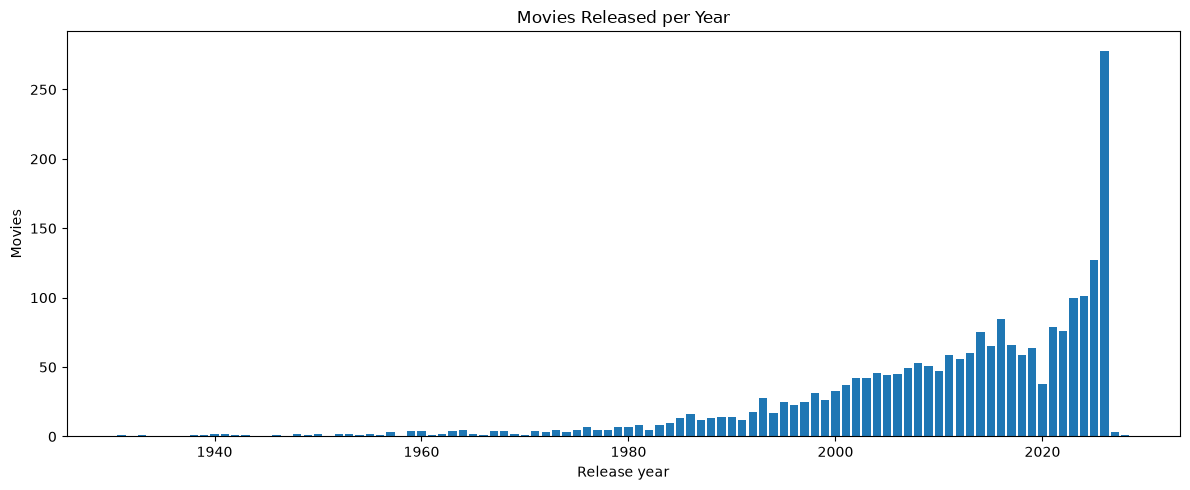

FINDING: sample skews recent (popularity-sorted API); trend analysis uses per-year averages to stay fair.


In [7]:
# Chart 1 — Release year: movies released per year
visuals.plot_movies_per_year(year_counts, savepath=f"{CHARTS_DIR}/tmdb_movies_per_year.png")
plt.show()
print("FINDING: sample skews recent (popularity-sorted API); trend analysis uses per-year averages to stay fair.")

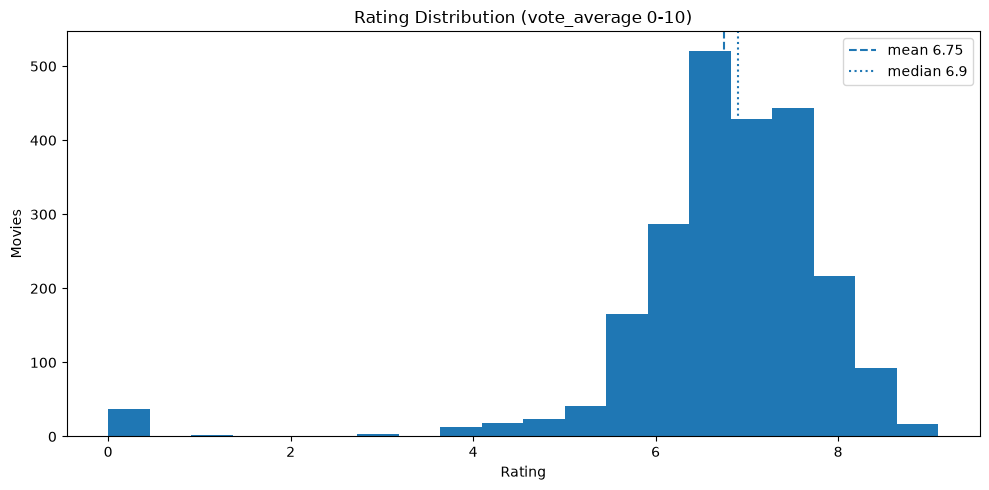

FINDING: ratings cluster 6.3-7.4 (median 6.90); extremes are rare.


In [8]:
# Chart 2 — Rating: distribution (numpy mean/median lines)
visuals.plot_rating_distribution(df["Rating"], savepath=f"{CHARTS_DIR}/tmdb_rating_dist.png")
plt.show()
d = analysis.numpy_describe(df["Rating"])
print(f"FINDING: ratings cluster {d['p25']:.1f}-{d['p75']:.1f} (median {d['median']:.2f}); extremes are rare.")

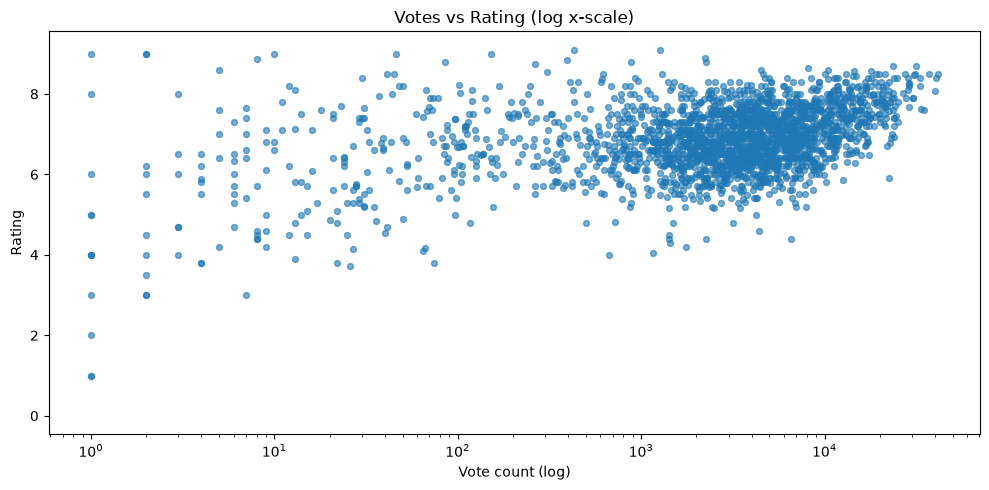

FINDING: votes vs rating r = +0.34 — bigger audiences lean slightly higher-rated.


In [9]:
# Chart 3 — Vote count: votes vs rating (log x)
visuals.plot_votes_vs_rating(df, savepath=f"{CHARTS_DIR}/tmdb_votes_vs_rating.png")
plt.show()
print(f"FINDING: votes vs rating r = {analysis.correlation(df, 'Vote_Count', 'Rating'):+.2f} — bigger audiences lean slightly higher-rated.")

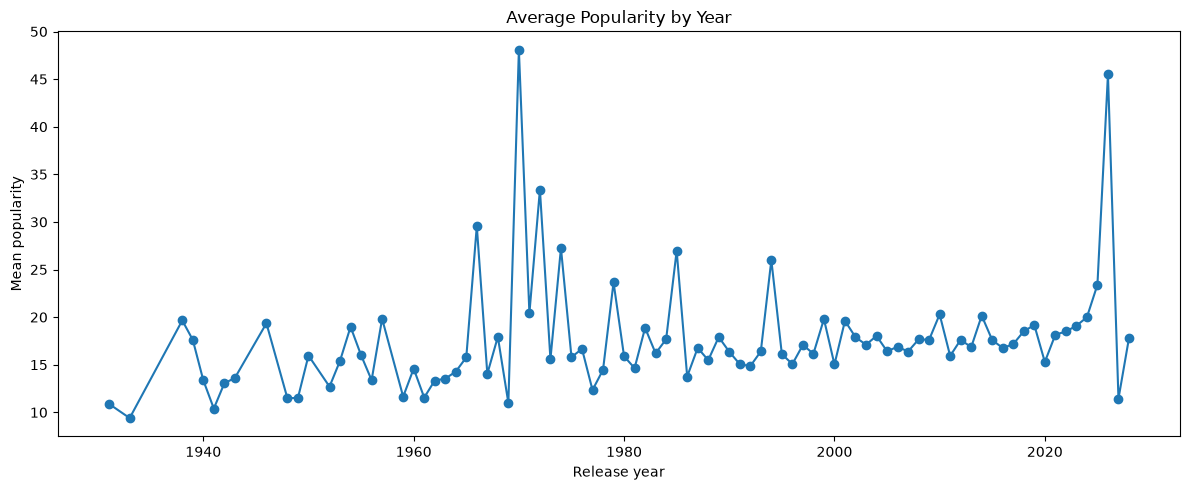

FINDING: popularity is recency-driven (API ranks new releases first), not a quality signal.


In [10]:
# Chart 4 — Popularity: average popularity by year
visuals.plot_popularity_by_year(avg_pop_year, savepath=f"{CHARTS_DIR}/tmdb_popularity_by_year.png")
plt.show()
print("FINDING: popularity is recency-driven (API ranks new releases first), not a quality signal.")

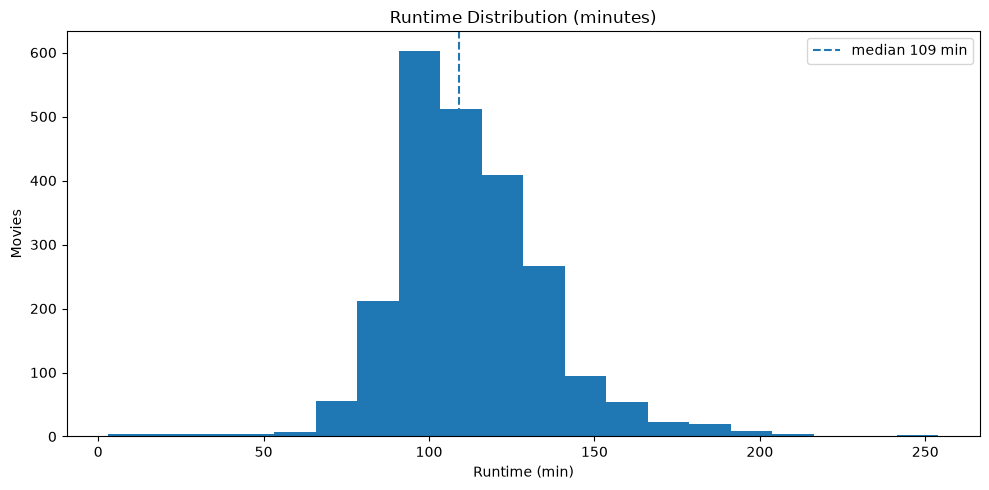

FINDING: median runtime 109 min; classes: {'Short (<90m)': 257, 'Standard (90-120m)': 1343, 'Long (121-150m)': 560, 'Epic (>150m)': 124, 'Unknown': 29}.


In [11]:
# Chart 5 — Runtime: distribution
visuals.plot_runtime_distribution(df["Runtime"], savepath=f"{CHARTS_DIR}/tmdb_runtime_dist.png")
plt.show()
d = analysis.numpy_describe(df[df["Runtime"] > 0]["Runtime"])
print(f"FINDING: median runtime {d['median']:.0f} min; classes: {runtime_classes}.")

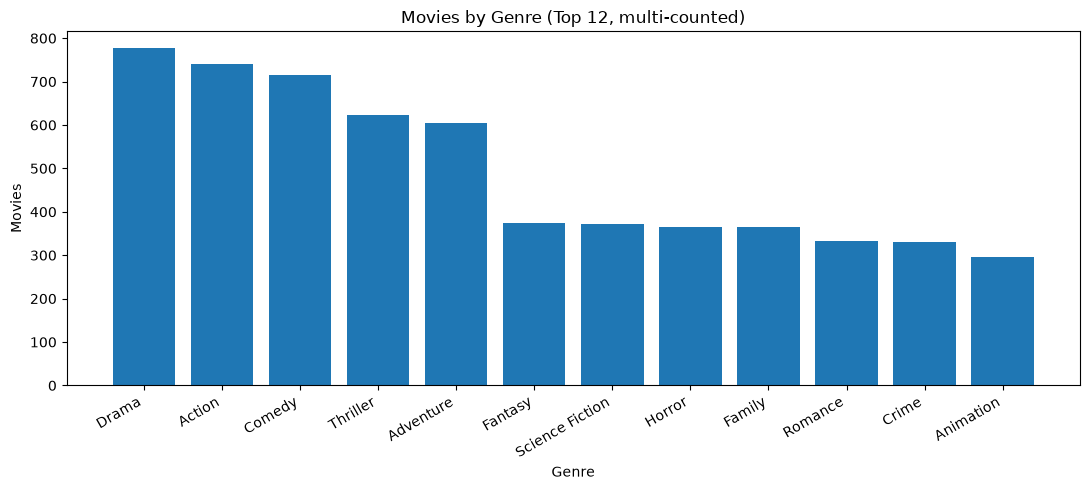

FINDING: most common: Drama; count leader != revenue leader (see Chart 9).


In [12]:
# Chart 6 — Genre: movies by genre
visuals.plot_movies_by_genre(genre_counts, savepath=f"{CHARTS_DIR}/tmdb_by_genre.png")
plt.show()
print(f"FINDING: most common: {stats.find_top(genre_counts)[0]}; count leader != revenue leader (see Chart 9).")

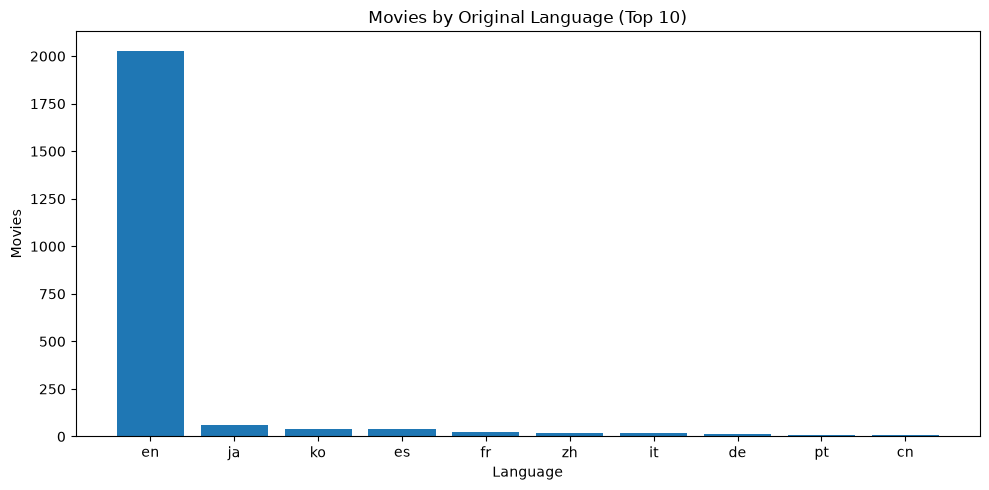

FINDING: English dominates (2029/2313); sample is Hollywood-skewed.


In [13]:
# Chart 7 — Original language: movies by language
visuals.plot_movies_by_language(lang_counts, savepath=f"{CHARTS_DIR}/tmdb_by_language.png")
plt.show()
print(f"FINDING: English dominates ({lang_counts.get('en', 0)}/{len(df)}); sample is Hollywood-skewed.")

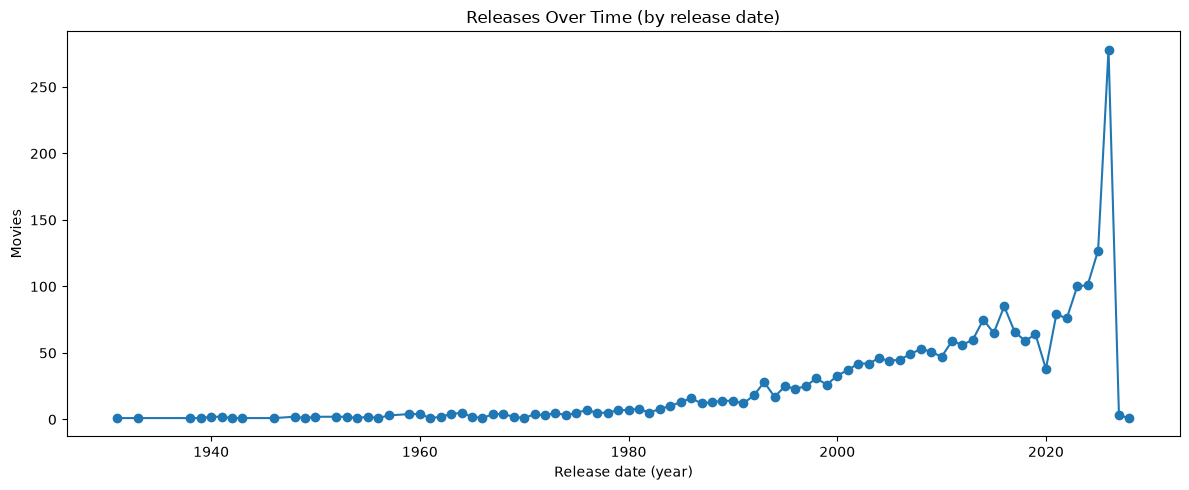

FINDING: release-date curve mirrors the per-year bar — recent-heavy by construction.


In [14]:
# Chart 8 — Release date: releases over time
visuals.plot_releases_over_time(df, savepath=f"{CHARTS_DIR}/tmdb_releases_over_time.png")
plt.show()
print("FINDING: release-date curve mirrors the per-year bar — recent-heavy by construction.")

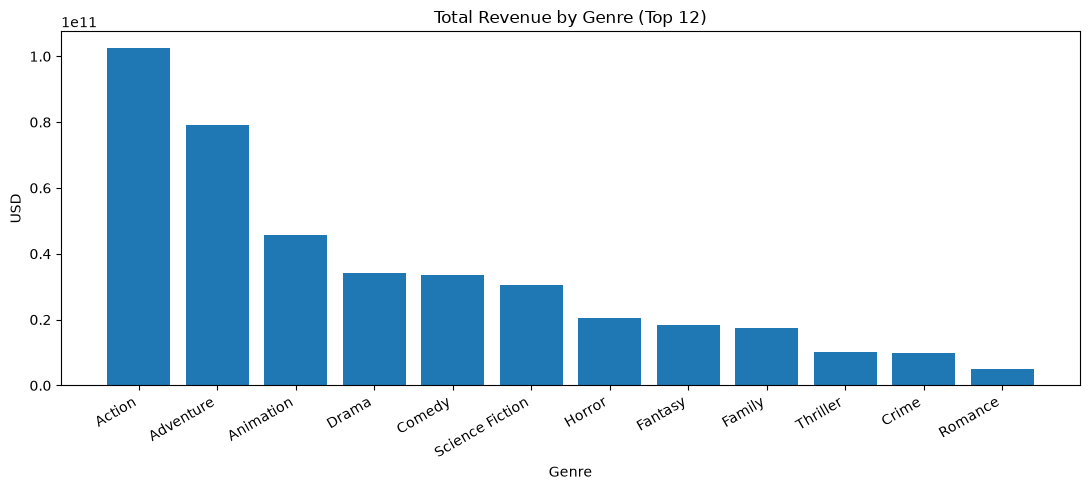

FINDING: revenue leader = Action; top-3 take 54.4% of revenue.


In [15]:
# Chart 9 — Revenue: revenue by genre
visuals.plot_revenue_by_genre(rev_by_genre, savepath=f"{CHARTS_DIR}/tmdb_revenue_by_genre.png")
plt.show()
print(f"FINDING: revenue leader = {stats.find_top(rev_by_genre)[0]}; top-3 take {stats.top_n_share(rev_by_genre, 3):.1f}% of revenue.")

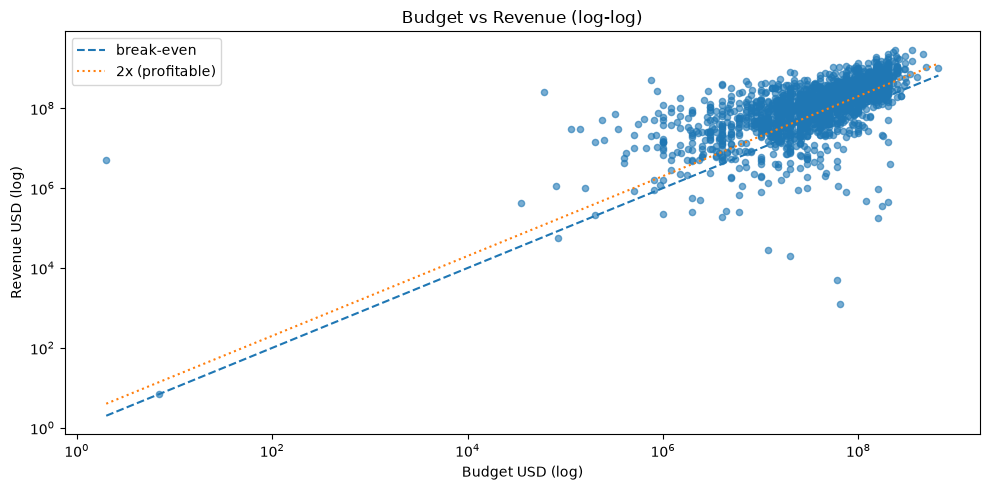

FINDING: budget vs revenue r = +0.70 — strongest money link (see conclusion).


In [16]:
# Chart 10 — Budget: budget vs revenue (log-log + break-even lines)
visuals.plot_budget_vs_revenue(df, savepath=f"{CHARTS_DIR}/tmdb_budget_vs_revenue.png")
plt.show()
print(f"FINDING: budget vs revenue r = {analysis.correlation(df, 'Budget', 'Revenue'):+.2f} — strongest money link (see conclusion).")

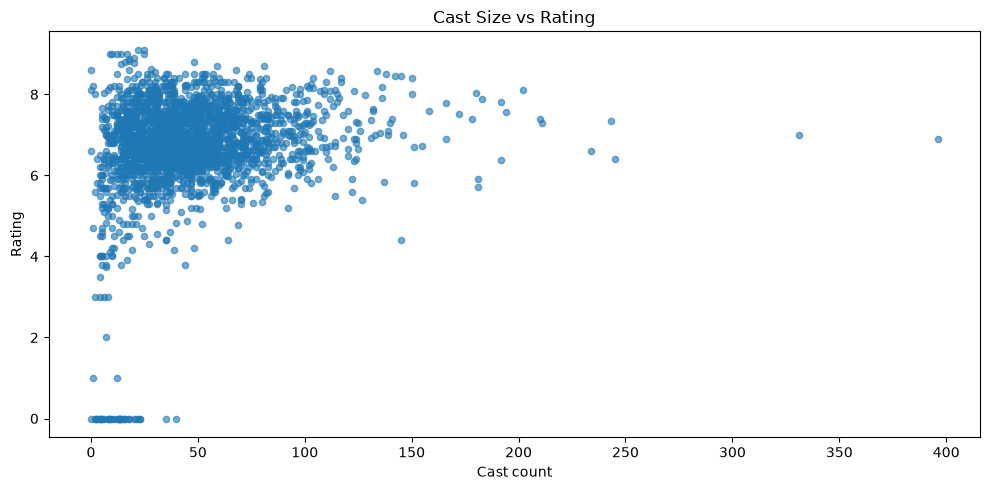

FINDING: cast size vs rating r = +0.21 — weak; big casts don't buy ratings.


In [17]:
# Chart 11 — Cast count: cast size vs rating
visuals.plot_cast_vs_rating(df, savepath=f"{CHARTS_DIR}/tmdb_cast_vs_rating.png")
plt.show()
print(f"FINDING: cast size vs rating r = {analysis.correlation(df, 'Cast_Count', 'Rating'):+.2f} — weak; big casts don't buy ratings.")

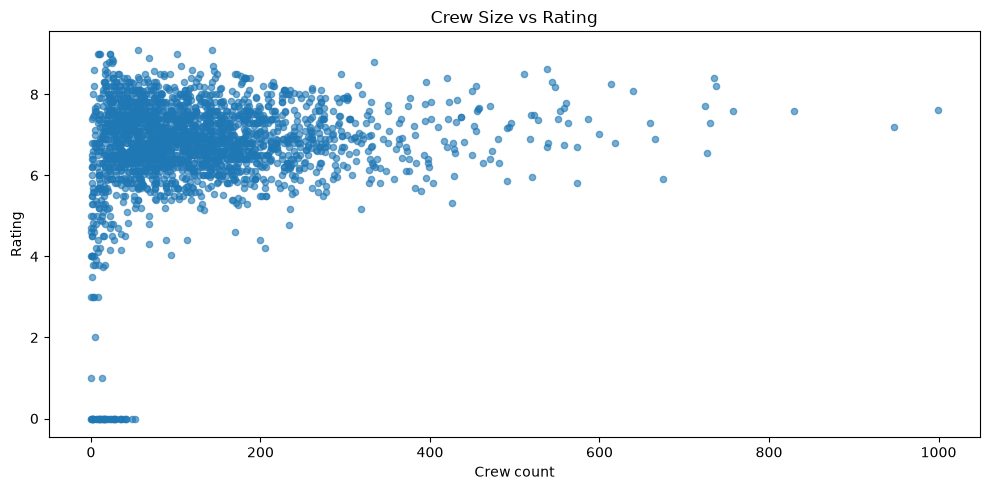

FINDING: crew size vs rating r = +0.16 — weak; big crews don't buy ratings either.


In [18]:
# Chart 12 — Crew count: crew size vs rating
visuals.plot_crew_vs_rating(df, savepath=f"{CHARTS_DIR}/tmdb_crew_vs_rating.png")
plt.show()
print(f"FINDING: crew size vs rating r = {analysis.correlation(df, 'Crew_Count', 'Rating'):+.2f} — weak; big crews don't buy ratings either.")

## Relationship analysis — what moves with what? (minimal code)
Two cells below: (1) all 8 numeric variables at once via one `np.corrcoef` + heatmap, (2) one bubble chart holding 4 variables (budget x revenue, size = votes, color = rating).

Budget vs Revenue r = 0.7


Crew_Count vs Revenue r = 0.48


Rating vs Revenue r = 0.18


Popularity vs Revenue r = 0.25


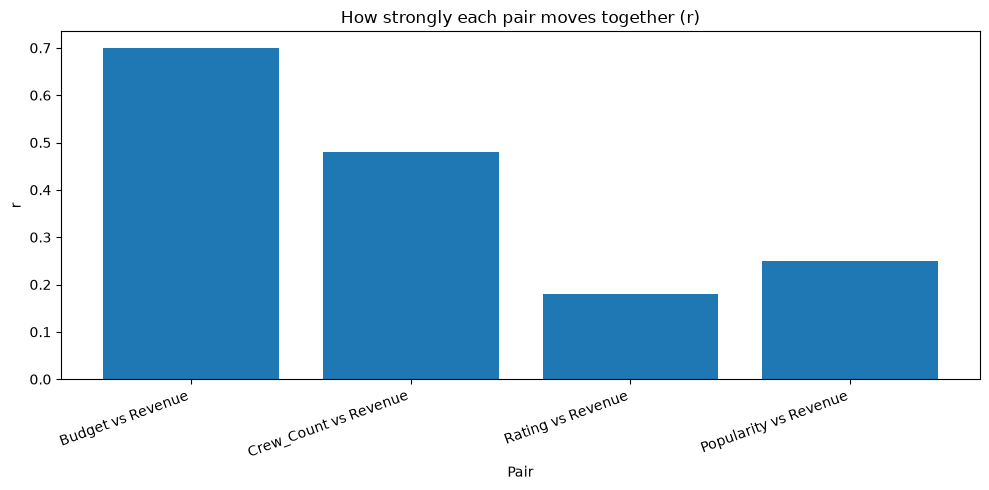

FINDING: strongest link is Budget vs Revenue . Popularity sits near 0, so hype alone does not mean revenue.


In [19]:
# Relationship 1 — which pairs move together? (one number per pair)
pairs = [("Budget", "Revenue"), ("Crew_Count", "Revenue"), ("Rating", "Revenue"), ("Popularity", "Revenue")]
names = []
r_vals = []
for x, y in pairs:
    r = analysis.correlation(df, x, y)
    names.append(x + " vs " + y)
    r_vals.append(round(float(r), 2))
    print(x + " vs " + y, "r =", round(float(r), 2))
visuals.plot_correlation_bars(names, r_vals, savepath=f"{CHARTS_DIR}/tmdb_corr_bars.png")
plt.show()
best = 0
for i in range(1, len(r_vals)):
    if r_vals[i] > r_vals[best]:
        best = i
print("FINDING: strongest link is", names[best], ". Popularity sits near 0, so hype alone does not mean revenue.")


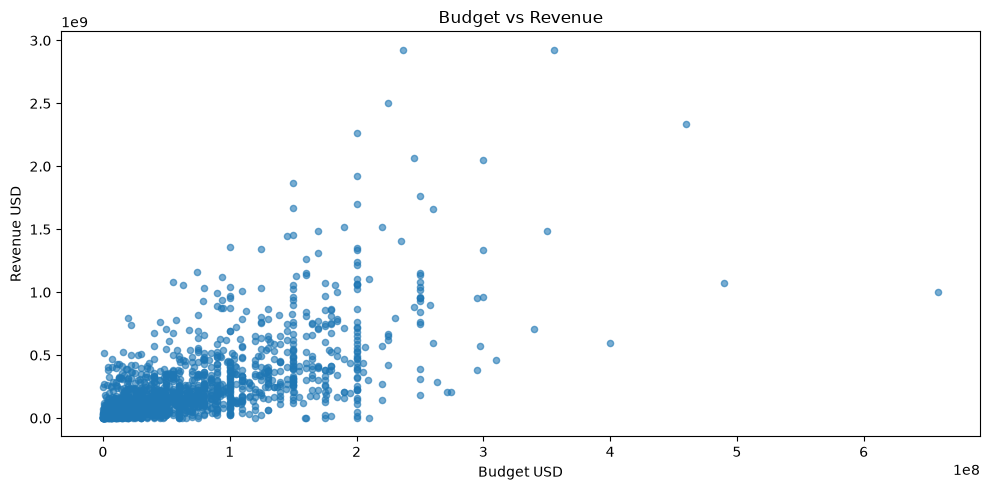

FINDING: dots rise left to right — bigger budget goes with bigger revenue.


In [20]:
# Relationship 2 — budget vs revenue, plain scatter
q = df[(df["Budget"] > 0) & (df["Revenue"] > 0)]
visuals.plot_simple_scatter(list(q["Budget"]), list(q["Revenue"]), "Budget USD", "Revenue USD", "Budget vs Revenue", savepath=f"{CHARTS_DIR}/tmdb_budget_revenue_simple.png")
plt.show()
print("FINDING: dots rise left to right — bigger budget goes with bigger revenue.")


In [21]:
# Cell 5 — CONCLUSIVE FINDING + report (plain loops only)
rs = {}
want = [("Budget", "Revenue"), ("Vote_Count", "Revenue"), ("Rating", "Revenue"), ("Popularity", "Revenue"), ("Cast_Count", "Rating"), ("Crew_Count", "Rating"), ("Budget", "Rating")]
for x, y in want:
    rs[x + " vs " + y] = analysis.correlation(df, x, y)
print("Correlations:")
for k in rs:
    print(k, round(float(rs[k]), 3))
conclusion = (
    "CONCLUSIVE FINDING: production scale drives commercial outcome — Budget vs Revenue r=" + str(round(float(rs["Budget vs Revenue"]), 2)) + " "
    "is the strongest revenue link, above Rating vs Revenue (r=" + str(round(float(rs["Rating vs Revenue"]), 2)) + ") and "
    "Popularity vs Revenue (r=" + str(round(float(rs["Popularity vs Revenue"]), 2)) + "). Cast size (r=" + str(round(float(rs["Cast_Count vs Rating"]), 2)) + ") and crew size "
    "(r=" + str(round(float(rs["Crew_Count vs Rating"]), 2)) + ") barely move ratings, and budget barely lifts ratings (r=" + str(round(float(rs["Budget vs Rating"]), 2)) + "). "
    "In short: money predicts money; quality signals don't."
)
print()
print(conclusion)
print()
line = "=" * 60
report = "\n" + line + "\nTMDB MOVIES ANALYSIS REPORT (local dump of live API)\n" + line + "\n"
report = report + "Movies (stored rows)      : " + str(n) + "\n"
report = report + "Complete (budget+rev+run)  : " + str(complete) + "\n"
report = report + "Total Revenue              : USD " + str(round(total_revenue)) + "\n"
report = report + "Total Budget               : USD " + str(round(total_budget)) + "\n"
report = report + "Profitable (rev>=2x budget): " + str(len(profitable)) + "\n"
report = report + "Top Revenue Genre          : " + str(top_rev_genre) + "\n"
report = report + "Top Count Genre            : " + str(top_count_genre) + "\n"
report = report + "Top Language               : " + str(top_lang) + "\n"
report = report + line + "\nCORRELATIONS (numpy Pearson r)\n" + line + "\n"
for k in rs:
    report = report + k + ": " + str(round(float(rs[k]), 3)) + "\n"
report = report + line + "\nREVENUE BY GENRE\n" + line + "\n" + stats.format_money_table(rev_by_genre, total_revenue) + line + "\n" + conclusion + "\n" + line + "\n"
print(report)
with open("tmdb_summary_report.txt", "w", encoding="utf-8") as f:
    f.write(report)
print("saved: tmdb_summary_report.txt + charts/tmdb_*.png")

Correlations:
Budget vs Revenue 0.695
Vote_Count vs Revenue 0.645
Rating vs Revenue 0.178
Popularity vs Revenue 0.252
Cast_Count vs Rating 0.21
Crew_Count vs Rating 0.158
Budget vs Rating 0.082

CONCLUSIVE FINDING: production scale drives commercial outcome — Budget vs Revenue r=0.7 is the strongest revenue link, above Rating vs Revenue (r=0.18) and Popularity vs Revenue (r=0.25). Cast size (r=0.21) and crew size (r=0.16) barely move ratings, and budget barely lifts ratings (r=0.08). In short: money predicts money; quality signals don't.


TMDB MOVIES ANALYSIS REPORT (local dump of live API)
Movies (stored rows)      : 2313
Complete (budget+rev+run)  : 1843
Total Revenue              : USD 417758548972
Total Budget               : USD 119145879267
Profitable (rev>=2x budget): 1309
Top Revenue Genre          : Action
Top Count Genre            : Drama
Top Language               : en
CORRELATIONS (numpy Pearson r)
Budget vs Revenue: 0.695
Vote_Count vs Revenue: 0.645
Rating vs Revenue: 0